# NHL: предсказать успешность команды в следующем сезоне

**Тестовое задание • 100 баллов**

Вы аналитик, которому после окончания сезона нужно оценить перспективы команды
на следующий год. Соберите таблицу с учебного сайта
[Scrape This Site - Hockey Teams](https://www.scrapethissite.com/pages/forms/),
изучите данные и постройте модель классификации.
В работе оцениваются корректность исследования и обоснованность решений.

Ориентир времени: 6-10 часов (знание хоккея не требуется).
Можно обращаться к документации и пользоваться вспомогательными инструментами.
Укажите, чем пользовались; отвечайте за правильность и понимание сданной работы.
Подтверждайте ответы результатами из своего ноутбука.

## Что сдавать

Выполненный IPynb с видимыми результатами и ответами и исходный `data/hockey_raw.csv` разместите на платформе githib.com.
Укажите имя, дату и использованные источники и инструменты в README.

## Что предсказывает модель

Одна строка признаков описывает команду в сезоне `t`.
`target=1`, если доля побед той же команды в сезоне `t+1` строго выше медианной
доли побед всех команд в сезоне `t+1`. В остальных случаях `target=0`.

Медиану считайте по полной исходной таблице будущего года до отбора пар.
В пары включайте одинаковые названия команды с разницей меток сезонов ровно в один год.
Строки без пары исключайте и учитывайте в описании данных.
Будущий `win_rate` и будущая медиана используются для построения target и анализа
готовых прогнозов. Признаки модели должны быть известны после сезона `t`.

## Схема проверки

Делите данные по году целевого сезона:

| Часть | target_year | Назначение |
|---|---|---|
| train | не позднее 2005 | Подготовка данных и обучение |
| validation | 2006-2008 | Сравнение вариантов и выбор решения |
| test | 2009-2011 | Одна итоговая оценка выбранного решения |

Основная метрика: ROC-AUC по вероятности класса 1.
На итоговом этапе также используйте F1 и accuracy при пороге 0.5.
Финальный test используйте после выбора решения на validation.

## Как оценивается работа

| Область | Баллы |
|---|---:|
| Сбор и понимание данных | 15 |
| Построение задачи и корректность проверки | 20 |
| Исследовательский анализ | 20 |
| Модели и эксперименты | 25 |
| Итоговая оценка и анализ ошибок | 15 |
| Ясность и воспроизводимость | 5 |
| **Всего** | **100** |

Ниже перечислены обязательные этапы работы. Внутри них вы самостоятельно выбираете
исследовательские вопросы, графики, признаки, обработку данных, эксперимент и способ
разбора ошибок. Оценивается качество решений, а не совпадение с эталонным маршрутом.
Сложность метода сама по себе не даёт преимущества. Корректный эксперимент может
получить полный балл и в случае отсутствия улучшения.

## Требования к сбору

Итоговая исходная таблица должна иметь столбцы `team`, `year`, `wins`, `losses`,
`ot_losses`, `win_rate`, `goals_for`, `goals_against`, `goal_diff`.
Самостоятельно исследуйте страницу и определите способ получения всей таблицы.

**Автор:** Adam Erik
**Дата:** 12.10.2026
**Использованные источники и инструменты:** данные — https://www.scrapethissite.com/pages/forms/; Python, requests, lxml, pandas, numpy, matplotlib, scikit-learn; документация pandas и scikit-learn; Claude Code (Anthropic) как ассистент при написании кода и текста.

In [1]:
# Ваши импорты и настройки
import time
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import sklearn
from lxml import html
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)

## Раздел 1. Сбор и понимание данных: 15 баллов

### 1.1. Соберите и сохраните данные

Соберите все страницы сайта в одну таблицу с указанными девятью столбцами.
Сохраните исходную выгрузку в `data/hockey_raw.csv`. Укажите URL и дату сбора,
число обработанных страниц и число строк. Покажите, как проверили,
что сбор не ограничился первой страницей и при повторном анализе можно читать CSV.

In [2]:
# 1.1. Сбор данных
URL = "https://www.scrapethissite.com/pages/forms/?page_num={page}&per_page=100"
PAGES = range(1, 7)
TABLE_XPATH = "/html/body/div/section/div/table"
COLUMNS = ["team", "year", "wins", "losses", "ot_losses",
           "win_rate", "goals_for", "goals_against", "goal_diff"]
RAW_CSV = Path("data/hockey_raw.csv")

rows = []
rows_per_page = {}
for page in PAGES:
    response = requests.get(URL.format(page=page), timeout=30)
    response.raise_for_status()
    table = html.fromstring(response.content).xpath(TABLE_XPATH)[0]

    page_rows = [[td.text_content().strip() for td in tr.xpath("./td")]
                 for tr in table.xpath(".//tr[@class='team']")]
    rows_per_page[page] = len(page_rows)
    rows.extend(page_rows)
    time.sleep(0.5)

RAW_CSV.parent.mkdir(exist_ok=True)
pd.DataFrame(rows, columns=COLUMNS).to_csv(RAW_CSV, index=False)

print("Дата сбора:", date.today())
print("Строк по страницам:", rows_per_page)
print("Всего строк:", len(rows))

Дата сбора: 2026-10-12
Строк по страницам: {1: 100, 2: 100, 3: 100, 4: 100, 5: 100, 6: 82}
Всего строк: 582


In [3]:
# Проверка: CSV читается, в нём все сезоны, а не только первая страница (1990-1994).
hockey_df = pd.read_csv(RAW_CSV)
print("Размер:", hockey_df.shape)
print("Годы:", hockey_df["year"].min(), "-", hockey_df["year"].max())
hockey_df.head()

Размер: (582, 9)
Годы: 1990 - 2011


,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
0,Boston Bruins,1990,44,24,NaN,0.550,299,264,35
1,Buffalo Sabres,1990,31,30,NaN,0.388,292,278,14
2,Calgary Flames,1990,46,26,NaN,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,NaN,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,NaN,0.425,273,298,-25


**Ответ 1.1:**

_Ваш ответ со ссылками на результаты собственной работы._

### 1.2. Проверьте качество таблицы

Изучите типы, пропуски и уникальность пары команда-год.
Добавьте не менее двух проверок согласованности, которые считаете важными
для последующего анализа. Покажите найденные особенности и обоснуйте
решения по их обработке. Сами проверки и способ представления результата выберите самостоятельно.

In [4]:
# 1.2. Типы и пропуски
hockey_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 582 entries, 0 to 581
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   team           582 non-null    str    
 1   year           582 non-null    int64  
 2   wins           582 non-null    int64  
 3   losses         582 non-null    int64  
 4   ot_losses      358 non-null    float64
 5   win_rate       582 non-null    float64
 6   goals_for      582 non-null    int64  
 7   goals_against  582 non-null    int64  
 8   goal_diff      582 non-null    int64  
dtypes: float64(2), int64(6), str(1)
memory usage: 41.1 KB


In [5]:
hockey_df.describe()

,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
count,582.000000,582.000000,582.000000,358.000000,582.000000,582.000000,582.000000,582.000000
mean,2000.907216,36.943299,32.353952,7.460894,0.458519,234.063574,234.063574,0.000000
std,6.330674,8.926081,8.411439,3.610191,0.102237,40.548915,42.510718,45.277458
min,1990.000000,9.000000,11.000000,0.000000,0.119000,115.000000,115.000000,-196.000000
25%,1996.000000,31.000000,27.000000,5.000000,0.390000,211.000000,207.000000,-27.000000
50%,2001.000000,38.000000,31.000000,7.000000,0.463000,231.000000,232.500000,4.000000
75%,2007.000000,43.000000,37.000000,10.000000,0.534000,254.000000,258.750000,31.000000
max,2011.000000,62.000000,71.000000,18.000000,0.756000,369.000000,414.000000,144.000000


In [6]:
# В каких годах пропущен ot_losses
missing_otl = hockey_df[hockey_df["ot_losses"].isna()]
print("Строк с пропуском ot_losses:", len(missing_otl))
print("Годы с пропусками:", missing_otl["year"].unique().tolist())

Строк с пропуском ot_losses: 224
Годы с пропусками: [1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998]


In [7]:
# Уникальность пары команда-год
duplicates = hockey_df[hockey_df.duplicated(["team", "year"])]
print("Дубликатов team-year:", len(duplicates))

Дубликатов team-year: 0


In [8]:
# Какие сезоны есть и сколько в них команд
teams_per_year = hockey_df.groupby("year")["team"].count()
print(teams_per_year)

year
1990    21
1991    22
1992    24
1993    26
1994    26
1995    26
1996    26
1997    26
1998    27
1999    28
2000    30
2001    30
2002    30
2003    30
2005    30
2006    30
2007    30
2008    30
2009    30
2010    30
2011    30
Name: team, dtype: int64


In [9]:
# Проверка согласованности 1: goal_diff = goals_for - goals_against
wrong_goal_diff = hockey_df[hockey_df["goal_diff"] != hockey_df["goals_for"] - hockey_df["goals_against"]]
print("Строк с неверным goal_diff:", len(wrong_goal_diff))

Строк с неверным goal_diff: 0


In [10]:
# Проверка согласованности 2: считается ли win_rate как wins / (wins + losses + ot_losses)?
check_df = hockey_df.copy()
check_df["games_in_table"] = check_df["wins"] + check_df["losses"] + check_df["ot_losses"].fillna(0)
check_df["naive_win_rate"] = (check_df["wins"] / check_df["games_in_table"]).round(3)
check_df["matches"] = (check_df["naive_win_rate"] - check_df["win_rate"]).abs() <= 0.001

# Если win_rate = wins / сыгранные игры, то сыгранные игры = wins / win_rate.
# Разница с games_in_table - игры, исход которых в таблице не записан.
check_df["games_played"] = (check_df["wins"] / check_df["win_rate"]).round()
check_df["unlisted_games"] = check_df["games_played"] - check_df["games_in_table"]

check_df.groupby("year")[["matches", "games_played", "unlisted_games"]].agg(["min", "max"])

matches        games_played       unlisted_games      
         min    max          min   max            min   max
year                                                       
1990   False  False         80.0  80.0            6.0  19.0
1991   False  False         80.0  80.0            5.0  15.0
1992   False  False         84.0  84.0            2.0  12.0
1993   False  False         84.0  84.0            3.0  17.0
1994   False  False         48.0  48.0            3.0  12.0
1995   False  False         82.0  82.0            4.0  18.0
1996   False  False         82.0  82.0            7.0  19.0
1997   False  False         82.0  82.0            8.0  18.0
1998   False  False         82.0  82.0            5.0  19.0
1999   False  False         82.0  82.0            6.0  19.0
2000   False  False         82.0  82.0            5.0  17.0
2001   False  False         82.0  82.0            4.0  16.0
2002   False  False         82.0  82.0            6.0  16.0
2003   False  False         82.0  82.0            7.0  20.0
2005    True   True         82.0  82.0            0.0   0.0
2006    True   True         82.0  82.0            0.0   0.0
2007    True   True         82.0  82.0            0.0   0.0
2008    True   True         82.0  82.0            0.0   0.0
2009    True   True         82.0  82.0            0.0   0.0
2010    True   True         82.0  82.0            0.0   0.0
2011    True   True         82.0  82.0            0.0   0.0

In [11]:
# Ручная проверка на одной строке
boston_1990 = check_df[(check_df["team"] == "Boston Bruins") & (check_df["year"] == 1990)]
print(boston_1990[["wins", "losses", "ot_losses", "win_rate", "games_played", "unlisted_games"]])
print("44 / (44 + 24 + 12) =", round(44 / 80, 3))

   wins  losses  ot_losses  win_rate  games_played  unlisted_games
0    44      24        NaN      0.55          80.0            12.0
44 / (44 + 24 + 12) = 0.55


In [12]:
# Проверка согласованности 3: команды, которые есть не во всех сезонах
seasons_per_team = hockey_df.groupby("team")["year"].agg(["min", "max", "count"])
n_seasons = hockey_df["year"].nunique()
print(seasons_per_team[seasons_per_team["count"] < n_seasons].sort_values("min"))

                          min   max  count
team                                      
Winnipeg Jets            1990  2011      7
Quebec Nordiques         1990  1994      5
Minnesota North Stars    1990  1992      3
Hartford Whalers         1990  1996      7
San Jose Sharks          1991  2011     20
Ottawa Senators          1992  2011     19
Tampa Bay Lightning      1992  2011     19
Mighty Ducks of Anaheim  1993  2005     12
Dallas Stars             1993  2011     18
Florida Panthers         1993  2011     18
Colorado Avalanche       1995  2011     16
Phoenix Coyotes          1996  2011     15
Carolina Hurricanes      1997  2011     14
Nashville Predators      1998  2011     13
Atlanta Thrashers        1999  2010     11
Columbus Blue Jackets    2000  2011     11
Minnesota Wild           2000  2011     11
Anaheim Ducks            2006  2011      6


In [13]:
# Winnipeg Jets встречается с разрывом
print(sorted(hockey_df.loc[hockey_df["team"] == "Winnipeg Jets", "year"]))

[1990, 1991, 1992, 1993, 1994, 1995, 2011]


**Ответ 1.2:**

_Ваш ответ со ссылками на результаты собственной работы._

## Раздел 2. Построение задачи и корректность проверки: 20 баллов

### 2.1. Постройте target

Соедините строку команды в сезоне `t` с той же командой ровно в сезоне `t+1`
и постройте target по определению задания. Покажите число полученных пар,
число и годы исключённых строк, а также число случаев равенства будущей медиане.
Проверьте расчёт вручную минимум на двух содержательно разных примерах.

In [14]:
# 2.1. Признаки сезона t. Все они известны сразу после окончания сезона t.
# Сыгранные игры: win_rate = wins / games_played, поэтому games_played = wins / win_rate
# (см. проверку 2 в 1.2: так учитываются ничьи, которых нет в таблице).
hockey_df["games_played"] = (hockey_df["wins"] / hockey_df["win_rate"]).round()
hockey_df["ties"] = hockey_df["games_played"] - hockey_df["wins"] - hockey_df["losses"] - hockey_df["ot_losses"].fillna(0)

# Сезоны разной длины (48, 80, 82, 84 игры), поэтому голы считаем на игру.
hockey_df["goals_for_per_game"] = hockey_df["goals_for"] / hockey_df["games_played"]
hockey_df["goals_against_per_game"] = hockey_df["goals_against"] / hockey_df["games_played"]
hockey_df["goal_diff_per_game"] = hockey_df["goal_diff"] / hockey_df["games_played"]

# Медиана win_rate каждого сезона по полной таблице.
season_median = hockey_df.groupby("year")["win_rate"].median()
goal_diff_median = hockey_df.groupby("year")["goal_diff_per_game"].median()

# Те же показатели относительно медианы своего сезона t.
hockey_df["win_rate_vs_median"] = hockey_df["win_rate"] - hockey_df["year"].map(season_median)
hockey_df["goal_diff_vs_median"] = hockey_df["goal_diff_per_game"] - hockey_df["year"].map(goal_diff_median)

In [15]:
# Соединяем строку сезона t с той же командой ровно в сезоне t+1.
current_df = hockey_df.copy()
current_df["target_year"] = current_df["year"] + 1

next_df = hockey_df[["team", "year", "win_rate"]].rename(
    columns={"year": "target_year", "win_rate": "next_win_rate"}
)

pairs_df = current_df.merge(next_df, on=["team", "target_year"], how="inner")
pairs_df["next_median"] = pairs_df["target_year"].map(season_median)
pairs_df["target"] = (pairs_df["next_win_rate"] > pairs_df["next_median"]).astype(int)

print("Исходных строк:", len(hockey_df))
print("Пар:", len(pairs_df))

Исходных строк: 582
Пар: 516


In [16]:
# Строки без пары
merged = hockey_df.merge(pairs_df[["team", "year"]], on=["team", "year"], how="left", indicator=True)
excluded_df = merged[merged["_merge"] == "left_only"]

print("Исключено строк:", len(excluded_df))
print(excluded_df.groupby("year")["team"].count())

Исключено строк: 66
year
1992     1
1994     1
1995     1
1996     1
2003    30
2005     1
2010     1
2011    30
Name: team, dtype: int64


In [17]:
# Исключённые строки вне 2003 и 2011 - это переименования и переезды команд
excluded_df[~excluded_df["year"].isin([2003, 2011])][["team", "year"]]

,team,year
51,Minnesota North Stars,1992
111,Quebec Nordiques,1994
144,Winnipeg Jets,1995
155,Hartford Whalers,1996
372,Mighty Ducks of Anaheim,2005
523,Atlanta Thrashers,2010


In [18]:
# Случаи равенства будущей медиане (по определению target = 0)
equal_to_median = pairs_df[pairs_df["next_win_rate"] == pairs_df["next_median"]]
print("Равенств будущей медиане:", len(equal_to_median))
print("Из них target = 1:", equal_to_median["target"].sum())

Равенств будущей медиане: 23
Из них target = 1: 0


In [19]:
# Ручная проверка: пересчитываем target напрямую из исходной таблицы.
def manual_check(team, year):
    next_season = hockey_df[hockey_df["year"] == year + 1]
    next_win_rate = next_season.loc[next_season["team"] == team, "win_rate"].iloc[0]
    next_median = next_season["win_rate"].median()
    manual_target = int(next_win_rate > next_median)

    pair = pairs_df[(pairs_df["team"] == team) & (pairs_df["year"] == year)].iloc[0]
    print(f"{team} {year}: win_rate(t+1) = {next_win_rate}, медиана(t+1) = {next_median}, "
          f"target вручную = {manual_target}, в pairs_df = {pair['target']}")


manual_check("Detroit Red Wings", 1993)    # явно выше медианы -> 1
manual_check("New Jersey Devils", 1991)    # ровно на медиане -> 0
manual_check("Toronto Maple Leafs", 1990)  # вырос с 0.287 до 0.375, но ниже медианы -> 0

Detroit Red Wings 1993: win_rate(t+1) = 0.688, медиана(t+1) = 0.4275, target вручную = 1, в pairs_df = 1
New Jersey Devils 1991: win_rate(t+1) = 0.476, медиана(t+1) = 0.476, target вручную = 0, в pairs_df = 0
Toronto Maple Leafs 1990: win_rate(t+1) = 0.375, медиана(t+1) = 0.444, target вручную = 0, в pairs_df = 0


**Ответ 2.1:**

Из 582 строк получено **516 пар** (команда в сезоне `t` + та же команда ровно в `t+1`).
Медиана будущего сезона считается по полной таблице этого сезона до отбора пар.

Исключено **66 строк**:
- 30 строк 2003 года: сезона 2004 в данных нет (локаут), пары 2003→2004 не существует;
- 30 строк 2011 года: последний год в данных, нет сезона 2012;
- 6 строк из-за смены названия или переезда: Minnesota North Stars 1992, Quebec Nordiques 1994,
  Winnipeg Jets 1995, Hartford Whalers 1996, Mighty Ducks of Anaheim 2005, Atlanta Thrashers 2010.
  Франшизы не объединяю, так как задание требует одинаковых названий.
  Название Winnipeg Jets встречается в 1995 и 2011 у разных клубов, но разница не равна одному году, поэтому ложной пары нет.

Равенств будущей медиане: **23**, у всех `target = 0`, потому что условие строгое («строго выше»).
Равенства возможны, потому что `win_rate` округлён до 3 знаков.

Ручная проверка (target пересчитан прямо из исходной таблицы и совпал с `pairs_df`):
- Detroit Red Wings 1993: 0.688 > 0.4275, значит 1 (явно сильная команда);
- New Jersey Devils 1991: 0.476 = 0.476, значит 0 (граничный случай равенства);
- Toronto Maple Leafs 1990: рост с 0.287 до 0.375, но 0.375 < 0.444, значит 0 (рост сам по себе не даёт класс 1).

### 2.2. Подготовьте временную проверку

Разделите пары на train, validation и test по заданным границам target_year.
Покажите для каждой части фактические годы, размер и долю класса 1.
Назовите минимум два столбца, которые появились при построении target,
но недоступны модели в момент прогноза. Объясните, почему случайное перемешивание
строк отвечало бы на другой вопрос, чем выбранная временная схема.

In [20]:
# 2.2. Временное разбиение по году целевого сезона
train_df = pairs_df[pairs_df["target_year"] <= 2005].copy()
val_df = pairs_df[pairs_df["target_year"].between(2006, 2008)].copy()
test_df = pairs_df[pairs_df["target_year"].between(2009, 2011)].copy()

parts = {"train": train_df, "validation": val_df, "test": test_df}
for name, part in parts.items():
    print(f"{name}: target_year {part['target_year'].unique().tolist()}, "
          f"строк {len(part)}, доля класса 1 = {part['target'].mean():.3f}")

train: target_year [1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003], строк 338, доля класса 1 = 0.491
validation: target_year [2006, 2007, 2008], строк 89, доля класса 1 = 0.472
test: target_year [2009, 2010, 2011], строк 89, доля класса 1 = 0.472


In [21]:
# Столбцы, появившиеся при построении target: известны только после сезона t+1,
# поэтому в признаки модели не попадают.
LEAKY_COLUMNS = ["next_win_rate", "next_median", "target"]
print(pairs_df[["team", "year", "target_year"] + LEAKY_COLUMNS].head(3))

             team  year  target_year  next_win_rate  next_median  target
0   Boston Bruins  1990         1991          0.450        0.444       1
1  Buffalo Sabres  1990         1991          0.388        0.444       0
2  Calgary Flames  1990         1991          0.388        0.444       0


**Ответ 2.2:**

| Часть | Фактические target_year | Строк | Доля класса 1 |
|---|---|---:|---:|
| train | 1991–2003 | 338 | 0.491 |
| validation | 2006–2008 | 89 | 0.472 |
| test | 2009–2011 | 89 | 0.472 |

Граница train задана как «не позднее 2005», но фактически train заканчивается на 2003:
без сезона 2004 нет пар 2003→2004 и 2004→2005. Validation и test по 89 строк вместо 90
из-за переименований Anaheim (2005→2006) и переезда Atlanta (2010→2011).

Недоступны модели в момент прогноза: `next_win_rate` (результат будущего сезона) и
`next_median` (медиана будущего сезона), а также сам `target`. Все три известны только после сезона `t+1`.

Случайное перемешивание отвечало бы на вопрос «насколько хорошо модель восстанавливает пропущенные
сезоны внутри уже известной истории». Модель обучалась бы на более поздних сезонах, чем те, на которых её проверяют.
Кроме того, одна и та же команда в соседних сезонах похожа (корреляция `win_rate` 0.56 в 3.2), и
её соседние сезоны попали бы в обе части. Временная схема отвечает на реальный вопрос: обучившись
только на прошлом, насколько хорошо модель предсказывает следующий сезон. Она также честно показывает
сдвиг между эпохами (отмена ничьих в 2005, см. 3.2), который случайное разбиение скрыло бы.

## Раздел 3. Исследовательский анализ: 20 баллов

### 3.1. Сформулируйте вопросы к данным

До построения основных графиков сформулируйте не менее двух собственных
исследовательских вопросов, связанных с будущей успешностью команд
или устройством данных. Для каждого запишите ожидаемый результат и объясните,
как ответ может повлиять на выбор признаков, обработку или интерпретацию модели.

In [22]:
# 3.1. Вопросы сформулированы в ответе ниже, код не нужен.

**Ответ 3.1:**

1. **Насколько успешность сохраняется от сезона к сезону?**
   Ожидание: связь положительная, но неполная, с возвратом к среднему: сильные команды в среднем
   немного слабеют, слабые немного усиливаются.
   Влияние: если связь сильная, текущий `win_rate` станет основным признаком и сильным ориентиром.
   Возврат к среднему означает, что крайние вероятности модели будут ошибаться чаще.

2. **Ранжирует ли разница голов будущий успех лучше, чем `win_rate`?**
   Ожидание: разница голов меньше зависит от случайности отдельных игр, поэтому ранжирует не хуже `win_rate`.
   Влияние: выбор признаков. Если оба признака сильно коррелированы, не стоит добавлять много похожих столбцов.

3. **Сопоставимы ли сезоны между собой?**
   Ожидание: нет. Длина сезона разная (в 1.2: 48–84 игры), до 2005 были ничьи, которые занижают `win_rate`.
   Влияние: признаки считать на игру и относительно медианы своего сезона, не использовать `ot_losses` с пропусками.

### 3.2. Проведите исследовательский анализ

Ответьте на вопросы из пункта 3.1 с помощью числовых сводок и визуализаций.
Количество и типы графиков выберите сами: их должно быть достаточно,
чтобы подтвердить выводы, а каждый график должен отвечать на сформулированный вопрос.
Покажите хотя бы одно конкретное наблюдение на уровне команды или сезона.
Для каждого вывода укажите ограничение интерпретации.

Корреляция win_rate(t) и win_rate(t+1): 0.561
Наклон линии регрессии: 0.543


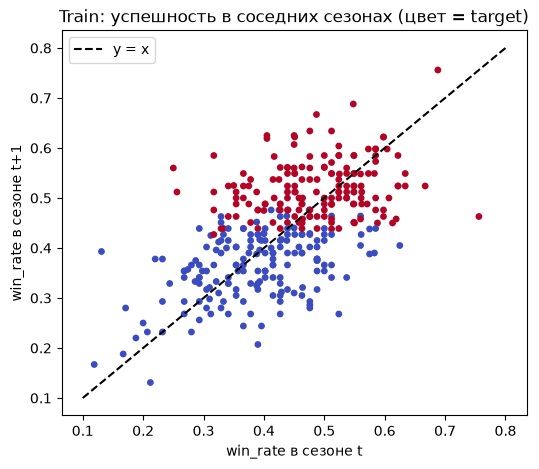

In [23]:
# 3.2. Весь анализ связи с target - только на train, чтобы validation и test не влияли на решения.
# Вопрос 1. Сохраняется ли успешность от сезона к сезону?
corr = train_df["win_rate"].corr(train_df["next_win_rate"])
slope = np.polyfit(train_df["win_rate"], train_df["next_win_rate"], 1)[0]
print("Корреляция win_rate(t) и win_rate(t+1):", round(corr, 3))
print("Наклон линии регрессии:", round(slope, 3))

plt.figure(figsize=(6, 5))
plt.scatter(train_df["win_rate"], train_df["next_win_rate"], c=train_df["target"], cmap="coolwarm", s=15)
plt.plot([0.1, 0.8], [0.1, 0.8], "k--", label="y = x")
plt.xlabel("win_rate в сезоне t")
plt.ylabel("win_rate в сезоне t+1")
plt.title("Train: успешность в соседних сезонах (цвет = target)")
plt.legend()
plt.show()

In [24]:
# Доля target = 1 по квартилям win_rate относительно медианы сезона t
quartile = pd.qcut(train_df["win_rate_vs_median"], 4)
print(train_df.groupby(quartile, observed=True)["target"].agg(["mean", "count"]))

                        mean  count
win_rate_vs_median                 
(-0.358, -0.0685]   0.200000     85
(-0.0685, 0.0]      0.377778     90
(0.0, 0.061]        0.569620     79
(0.061, 0.323]      0.833333     84


In [25]:
# Наблюдение на уровне команды: самые большие изменения win_rate между сезонами
change = train_df["next_win_rate"] - train_df["win_rate"]
biggest_changes = train_df.loc[change.abs().nlargest(5).index]
biggest_changes[["team", "year", "win_rate", "next_win_rate", "next_median", "target"]]

,team,year,win_rate,next_win_rate,next_median,target
36,Quebec Nordiques,1991,0.250,0.560,0.476,1
124,Detroit Red Wings,1995,0.756,0.463,0.427,1
123,Dallas Stars,1995,0.317,0.585,0.427,1
59,San Jose Sharks,1992,0.131,0.393,0.464,0
231,Florida Panthers,1999,0.524,0.268,0.445,0


win_rate: ROC-AUC на train = 0.778
goal_diff_per_game: ROC-AUC на train = 0.776


goals_for_per_game: ROC-AUC на train = 0.661
goals_against_per_game: ROC-AUC на train = 0.328
ties: ROC-AUC на train = 0.512
Корреляция win_rate и goal_diff_per_game: 0.942


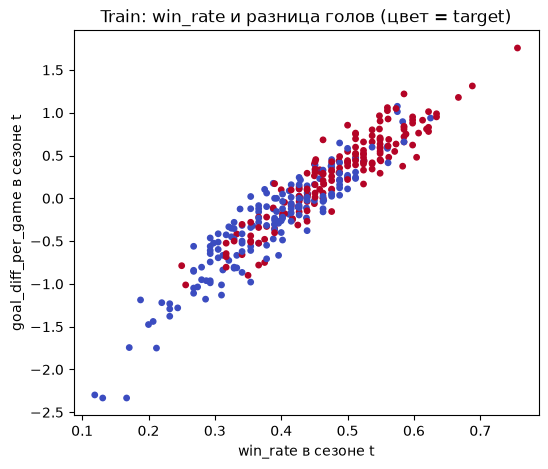

In [26]:
# Вопрос 2. Лучше ли разница голов ранжирует будущий успех, чем win_rate?
for feature in ["win_rate", "goal_diff_per_game", "goals_for_per_game", "goals_against_per_game", "ties"]:
    auc = roc_auc_score(train_df["target"], train_df[feature])
    print(f"{feature}: ROC-AUC на train = {auc:.3f}")

print("Корреляция win_rate и goal_diff_per_game:",
      round(train_df["win_rate"].corr(train_df["goal_diff_per_game"]), 3))

plt.figure(figsize=(6, 5))
plt.scatter(train_df["win_rate"], train_df["goal_diff_per_game"], c=train_df["target"], cmap="coolwarm", s=15)
plt.xlabel("win_rate в сезоне t")
plt.ylabel("goal_diff_per_game в сезоне t")
plt.title("Train: win_rate и разница голов (цвет = target)")
plt.show()

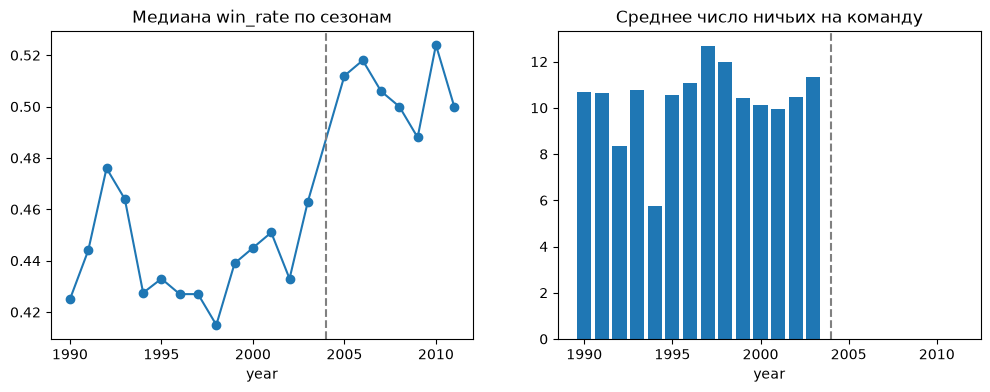

train: медиана win_rate(t) = 0.439, медиана win_rate_vs_median = 0.000
validation: медиана win_rate(t) = 0.512, медиана win_rate_vs_median = 0.000
test: медиана win_rate(t) = 0.500, медиана win_rate_vs_median = 0.000


In [27]:
# Вопрос 3. Сопоставимы ли сезоны между собой?
# Здесь используются только показатели сезонов (без target), поэтому смотрим все годы.
median_by_year = hockey_df.groupby("year")["win_rate"].median()
ties_by_year = hockey_df.groupby("year")["ties"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(median_by_year.index, median_by_year.values, marker="o")
axes[0].set_title("Медиана win_rate по сезонам")
axes[1].bar(ties_by_year.index, ties_by_year.values)
axes[1].set_title("Среднее число ничьих на команду")
for ax in axes:
    ax.axvline(2004, color="grey", linestyle="--")
    ax.set_xlabel("year")
plt.show()

for name, part in parts.items():
    print(f"{name}: медиана win_rate(t) = {part['win_rate'].median():.3f}, "
          f"медиана win_rate_vs_median = {part['win_rate_vs_median'].median():.3f}")

**Ответ 3.2:**

**Вопрос 1.** Корреляция `win_rate(t)` и `win_rate(t+1)` на train равна **0.561**, наклон регрессии **0.543**.
Успешность сохраняется, но с сильным возвратом к среднему: на графике облако лежит положе линии y = x.
По квартилям `win_rate_vs_median` доля `target = 1` растёт монотонно: 0.20 → 0.38 → 0.57 → 0.83.
Наблюдение на уровне команд: Quebec Nordiques 1991 выросли с 0.250 до 0.560, Florida Panthers 1999
упали с 0.524 до 0.268, а Detroit Red Wings 1995 упали с 0.756 до 0.463, но остались выше медианы
(0.427), поэтому их target = 1.
*Ограничение:* это корреляция по эпохе 1990–2003. Причины резких изменений (составы, травмы)
в данных отсутствуют.

**Вопрос 2.** ROC-AUC на train: `win_rate` 0.778, `goal_diff_per_game` 0.776, `goals_for_per_game` 0.661,
`goals_against_per_game` 0.328 (то есть 0.672 в обратную сторону), `ties` 0.512 (сигнала нет).
Корреляция `win_rate` и `goal_diff_per_game` **0.942**: признаки почти дублируют друг друга.
Вывод: для модели берём `win_rate` и `goal_diff_per_game`, а не забитые и пропущенные отдельно
(разница голов — их линейная комбинация).
*Ограничение:* AUC одного признака на train ничего не говорит о его вкладе в комбинации.
Из-за коллинеарности коэффициенты модели нельзя интерпретировать по отдельности.

**Вопрос 3.** Медиана `win_rate` по сезонам до 2003 года 0.42–0.48, с 2005 года 0.49–0.52.
Ничьи после 2004 исчезают (правый график). Медиана `win_rate(t)`: train 0.439, validation 0.512, test 0.500.
Абсолютный `win_rate` в train и в validation/test находится на разных шкалах, а отклонение от
медианы сезона во всех частях центрировано в 0.
Вывод: модель на абсолютных признаках рискует сдвинуть порог, относительные признаки этот сдвиг убирают
(проверяется в 4.3).
*Ограничение:* связь сдвига с отменой ничьих видна по данным (ничьи = 0 с 2005),
но причину смены правил таблица не содержит. Сезон 1994 короткий (48 игр), поэтому его `win_rate` шумнее.

## Раздел 4. Модели и эксперименты: 25 баллов

### 4.1. Постройте ориентиры

На train обучите простой константный baseline и оцените его на validation.
Отдельно используйте текущий `win_rate` как простую оценку для ранжирования
будущего класса. Посчитайте ROC-AUC обоих ориентиров и объясните,
какую планку задаёт каждый из них для обучаемой модели.

In [28]:
# 4.1. Константный baseline: всегда предсказывает долю класса 1 из train
dummy = DummyClassifier(strategy="prior")
dummy.fit(train_df[["win_rate"]], train_df["target"])
dummy_val_proba = dummy.predict_proba(val_df[["win_rate"]])[:, 1]

print("Константа P(target=1):", round(dummy_val_proba[0], 3))
print("ROC-AUC константы на validation:", roc_auc_score(val_df["target"], dummy_val_proba))

# Текущий win_rate как оценка для ранжирования (без обучения)
print("ROC-AUC win_rate на validation:", round(roc_auc_score(val_df["target"], val_df["win_rate"]), 3))

Константа P(target=1): 0.491
ROC-AUC константы на validation: 0.5
ROC-AUC win_rate на validation: 0.757


**Ответ 4.1:**

Константный baseline на train выдаёт всем строкам P(target=1) = 0.491. Его ROC-AUC на validation
ровно **0.5**: одинаковые оценки ничего не ранжируют. Это нижняя планка: обучаемая модель должна
хоть как-то упорядочивать команды.

Текущий `win_rate` как оценка без обучения даёт ROC-AUC **0.757**. Это содержательная планка:
обучаемая модель имеет смысл, только если она даёт больше, чем «сильные сейчас останутся сильными».

### 4.2. Постройте первую модель

Обучите логистическую регрессию. Самостоятельно выберите признаки и обоснуйте выбор.
Обработку пропусков и масштабирование включите в Pipeline и обучайте только на train.
Посчитайте ROC-AUC на validation и сравните с обоими ориентирами.
Объясните результат без использования test.

In [29]:
# 4.2. Логистическая регрессия
FEATURES_V1 = ["win_rate", "goal_diff_per_game"]


def make_model():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(random_state=SEED),
    )


model_v1 = make_model().fit(train_df[FEATURES_V1], train_df["target"])
val_proba_v1 = model_v1.predict_proba(val_df[FEATURES_V1])[:, 1]

print("ROC-AUC модели на validation:", round(roc_auc_score(val_df["target"], val_proba_v1), 3))
print("Коэффициенты (после масштабирования):", dict(zip(FEATURES_V1, model_v1[-1].coef_[0].round(3).tolist())))
print("Доля прогнозов 1 при пороге 0.5:", round((val_proba_v1 >= 0.5).mean(), 3))
print("Фактическая доля класса 1:", round(val_df["target"].mean(), 3))

ROC-AUC модели на validation: 0.771
Коэффициенты (после масштабирования): {'win_rate': 0.78, 'goal_diff_per_game': 0.494}
Доля прогнозов 1 при пороге 0.5: 0.697
Фактическая доля класса 1: 0.472


**Ответ 4.2:**

Признаки: `win_rate` (текущий результат, лучший одиночный признак на train) и `goal_diff_per_game`
(вторая мера силы команды, на игру из-за разной длины сезонов).
Не взяты: `goals_for` и `goals_against` по отдельности (их разность уже есть), `ties` (AUC 0.51 на train),
`ot_losses` (пропуск в 1990–1998 означает «показатель не вёлся», и заполнение медианой придумало бы значения).
`SimpleImputer` оставлен в Pipeline как защита, в выбранных признаках пропусков нет.
Pipeline (imputer → scaler → логистическая регрессия) обучен только на train.

ROC-AUC на validation **0.771**: выше константы (0.5) и выше `win_rate` (0.757) на 0.014.
Прирост маленький: validation — это 89 строк, и такая разница может быть шумом.
Это ожидаемо: признаки коррелированы на 0.94, и второй даёт немного новой информации.

Проблема видна без test: при пороге 0.5 модель прогнозирует класс 1 для **69.7%** команд validation,
хотя фактическая доля 47.2%. Это сдвиг шкалы `win_rate` из вопроса 3: модель выучила порог на эпохе
с ничьими, где медиана 0.44, а в validation медиана 0.51.

### 4.3. Проведите собственный эксперимент

Выберите одно осмысленное изменение: состав признаков, способ обработки данных,
параметры или другой алгоритм. До запуска запишите ожидаемый эффект и его причину.
Изменяйте одну понятную часть решения, сравните варианты на validation
и зафиксируйте выбор финальной модели до просмотра test.
Дополнительные эксперименты допустимы, но их количество само по себе не оценивается.

**Эксперимент 4.3 (записано до запуска).**

Изменение: заменяем признаки на их отклонение от медианы своего сезона t
(`win_rate_vs_median`, `goal_diff_vs_median`); модель, обработка и параметры те же.

Ожидание: в 3.2 видно, что медиана win_rate в train (сезоны с ничьими) около 0.43,
а в validation и test около 0.51. Модель v1 выучила порог на старой шкале и поэтому
на validation слишком часто прогнозирует класс 1. Относительные признаки убирают этот сдвиг.
ROC-AUC почти не изменится: внутри validation все сезоны одной эпохи, и сдвиг одинаков для всех строк,
а ранжирование от общего сдвига не зависит. Доля прогнозов 1 должна приблизиться к фактической,
а accuracy при пороге 0.5 вырасти.

Правило выбора: основная метрика ROC-AUC. Если разница ROC-AUC меньше 0.01
(при 89 строках это шум), выбираем вариант с лучшей калибровкой доли прогнозов 1.

In [30]:
# 4.3. Вариант v2: те же признаки относительно медианы сезона t
FEATURES_V2 = ["win_rate_vs_median", "goal_diff_vs_median"]

model_v2 = make_model().fit(train_df[FEATURES_V2], train_df["target"])
val_proba_v2 = model_v2.predict_proba(val_df[FEATURES_V2])[:, 1]

for name, proba in [("v1 абсолютные", val_proba_v1), ("v2 относительные", val_proba_v2)]:
    predicted = (proba >= 0.5).astype(int)
    print(f"{name}: ROC-AUC = {roc_auc_score(val_df['target'], proba):.3f}, "
          f"accuracy = {accuracy_score(val_df['target'], predicted):.3f}, "
          f"доля прогнозов 1 = {predicted.mean():.3f}")

v1 абсолютные: ROC-AUC = 0.771, accuracy = 0.708, доля прогнозов 1 = 0.697
v2 относительные: ROC-AUC = 0.768, accuracy = 0.719, доля прогнозов 1 = 0.483


In [31]:
# Фиксируем финальную модель до просмотра test
FINAL_FEATURES = FEATURES_V2
final_model = model_v2
print("Финальные признаки:", FINAL_FEATURES)
print(final_model)

Финальные признаки: ['win_rate_vs_median', 'goal_diff_vs_median']
Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(random_state=42))])


**Ответ 4.3:**

| Вариант | ROC-AUC | accuracy | Доля прогнозов 1 |
|---|---:|---:|---:|
| v1: абсолютные признаки | 0.771 | 0.708 | 0.697 |
| v2: относительно медианы сезона | 0.768 | 0.719 | 0.483 |

Ожидание подтвердилось. ROC-AUC почти не изменился (−0.003, меньше заранее заданного порога 0.01),
доля прогнозов 1 приблизилась к фактической 0.472, accuracy выросла.
По правилу выбора финальная модель — **v2** (`win_rate_vs_median`, `goal_diff_vs_median`,
та же логистическая регрессия). Выбор зафиксирован до просмотра test.

## Раздел 5. Итоговая оценка и анализ ошибок: 15 баллов

### 5.1. Проведите итоговую оценку

Зафиксируйте выбранную модель, признаки и параметры, затем один раз оцените её на test.
Покажите ROC-AUC, F1 и accuracy при пороге 0.5 для выбранной модели
и сопоставимых baseline. Объясните различия между метриками и сравните
результаты validation и test. После этого не меняйте выбранное решение.

In [32]:
# 5.1. Однократная оценка на test
def evaluate(name, y_true, score, predicted):
    return {
        "model": name,
        "roc_auc": roc_auc_score(y_true, score),
        "f1": f1_score(y_true, predicted, zero_division=0),
        "accuracy": accuracy_score(y_true, predicted),
    }


def evaluate_all(df):
    y_true = df["target"]
    dummy_proba = dummy.predict_proba(df[["win_rate"]])[:, 1]
    final_proba = final_model.predict_proba(df[FINAL_FEATURES])[:, 1]
    rows = [
        evaluate("константа", y_true, dummy_proba, (dummy_proba >= 0.5).astype(int)),
        # Правило: «выше медианы сейчас - будет выше медианы и дальше»
        evaluate("win_rate", y_true, df["win_rate"], (df["win_rate_vs_median"] > 0).astype(int)),
        evaluate("финальная модель", y_true, final_proba, (final_proba >= 0.5).astype(int)),
    ]
    return pd.DataFrame(rows).set_index("model").round(3)


print("Validation:")
print(evaluate_all(val_df))
print()
print("Test:")
print(evaluate_all(test_df))

Validation:
                  roc_auc     f1  accuracy
model                                     
константа           0.500  0.000     0.528
win_rate            0.757  0.706     0.719
финальная модель    0.768  0.706     0.719

Test:
                  roc_auc     f1  accuracy
model                                     
константа           0.500  0.000     0.528
win_rate            0.740  0.651     0.674
финальная модель    0.748  0.651     0.663


**Ответ 5.1:**

| test | ROC-AUC | F1 | accuracy |
|---|---:|---:|---:|
| константа | 0.500 | 0.000 | 0.528 |
| win_rate (правило «выше медианы сейчас» для порога) | 0.740 | 0.651 | 0.674 |
| финальная модель | 0.748 | 0.651 | 0.663 |

Почему метрики различаются. ROC-AUC оценивает только порядок вероятностей и от порога не зависит.
F1 смотрит на класс 1: у константы он 0, потому что она всегда прогнозирует 0. Accuracy зависит от порога
и баланса классов: константа получает 0.528 просто за счёт доли класса 0.

Модель на test ранжирует чуть лучше `win_rate` (ROC-AUC +0.008). При пороге 0.5 её F1 совпадает
с простым правилом, а accuracy на одну строку ниже. На validation модель и правило дали одинаковые F1 и accuracy.
Модель по сути повторяет правило «команда выше медианы останется выше медианы».

Validation → test: ROC-AUC модели 0.768 → 0.748, у `win_rate` 0.757 → 0.740. Падение одинаковое
у обоих, и при 89 строках в каждой части оно сопоставимо с разбросом между выборками. Сильного
переобучения на validation не видно.

### 5.2. Разберите ошибки

Выберите от трёх до пяти ошибок финальной модели по явно указанному принципу.
Это могут быть наиболее уверенные ошибки, отдельный тип ошибки или другой
обоснованный набор. Покажите идентификаторы строк, вероятности и значения,
необходимые для анализа. Найдите общие черты и различия; отделите факты
из таблицы от гипотез и назовите данные, нужные для проверки одной гипотезы.

In [33]:
# 5.2. Принцип отбора: самые уверенные ошибки финальной модели на test
test_result = test_df.copy()
test_result["proba"] = final_model.predict_proba(test_result[FINAL_FEATURES])[:, 1]
test_result["predicted"] = (test_result["proba"] >= 0.5).astype(int)

errors = test_result[test_result["predicted"] != test_result["target"]].copy()
errors["confidence"] = (errors["proba"] - 0.5).abs()

print("Ошибок на test:", len(errors), "из", len(test_result))
top_errors = errors.sort_values("confidence", ascending=False).head(5)
top_errors[["team", "year", "win_rate", "goal_diff_per_game", "win_rate_vs_median", "goal_diff_vs_median",
            "proba", "predicted", "target", "next_win_rate", "next_median"]].round(3)

Ошибок на test: 30 из 89


,team,year,win_rate,goal_diff_per_game,win_rate_vs_median,goal_diff_vs_median,proba,predicted,target,next_win_rate,next_median
429,Boston Bruins,2008,0.646,0.951,0.146,0.921,0.863,1,0,0.476,0.488
435,Colorado Avalanche,2008,0.390,-0.707,-0.110,-0.738,0.191,0,1,0.524,0.488
479,Phoenix Coyotes,2009,0.610,0.280,0.122,0.268,0.768,1,0,0.524,0.524
474,New Jersey Devils,2009,0.585,0.378,0.097,0.366,0.741,1,0,0.463,0.524
483,Tampa Bay Lightning,2009,0.415,-0.524,-0.073,-0.537,0.270,0,1,0.561,0.524


**Ответ 5.2:**

Принцип отбора: **5 самых уверенных ошибок** финальной модели на test (максимум |p − 0.5|).
Всего ошибок 30 из 89.

Факты из таблицы:
- **Boston Bruins 2008**, p = 0.863, прогноз 1, факт 0. Сильнейшая команда (`win_rate` 0.646, +0.95 гола за игру).
  В 2009: 0.476 при медиане 0.488, разница меньше одной победы (1/82 ≈ 0.012).
- **Phoenix Coyotes 2009**, p = 0.768, прогноз 1, факт 0. В 2010: 0.524, **ровно** медиана 0.524.
  Target = 0 только из-за строгого условия.
- **New Jersey Devils 2009**, p = 0.741, прогноз 1, факт 0. Упали с 0.585 до 0.463 при медиане 0.524.
- **Colorado Avalanche 2008**, p = 0.191, прогноз 0, факт 1. Рост с 0.390 до 0.524 при медиане 0.488.
- **Tampa Bay Lightning 2009**, p = 0.270, прогноз 0, факт 1. Рост с 0.415 до 0.561 при медиане 0.524.

Общее: все пять — команды с ярко выраженной силой или слабостью в сезоне `t` (|`goal_diff_vs_median`| от 0.27 до 0.92),
которые в следующем сезоне перешли на другую сторону медианы. Это возврат к среднему, который сильнее,
чем учитывает модель.
Различия: две ошибки (Boston, Phoenix) — граничные, будущий результат в пределах одной победы
от медианы. Их нельзя назвать ошибкой оценки силы. Три остальные — реальные резкие изменения на 0.12–0.15.

Гипотезы (не проверены по таблице):
1. Резкие изменения (Colorado, Tampa Bay, New Jersey) вызваны изменениями состава: травмы, обмены, вратарь.
2. Граничные ошибки — это случайность при пороге ровно на медиане, и улучшить их по этим признакам нельзя.

Для проверки гипотезы 1 нужны данные по игрокам за сезоны `t` и `t+1`: число игр, пропущенных из-за
травм ключевыми игроками, и смены основного вратаря. Если слабый сезон Colorado 2008 совпадает с большим
числом пропусков из-за травм, рост в 2009 объясняется возвращением игроков.

## Раздел 6. Выводы и воспроизводимость: 5 баллов

### 6.1. Сформулируйте выводы

Сформулируйте основные выводы и ограничения работы со ссылками на свои графики,
строки и метрики. Опишите минимум два решения, которые вы изменили
или подтвердили после получения результатов. Назовите одно улучшение,
которое вы сознательно не стали выполнять, и объясните причину.
Убедитесь, что последовательность работы и финальные параметры можно воспроизвести.

In [34]:
# 6.1. Итоговые параметры для воспроизведения
print("SEED:", SEED)
print("pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)
print("Пар train/validation/test:", len(train_df), len(val_df), len(test_df))
print("Финальные признаки:", FINAL_FEATURES)
print("Модель:", final_model)

SEED: 42
pandas: 3.0.6 | scikit-learn: 1.9.1
Пар train/validation/test: 338 89 89
Финальные признаки: ['win_rate_vs_median', 'goal_diff_vs_median']
Модель: Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(random_state=42))])


**Ответ 6.1:**

Основные выводы:
- Будущую успешность команды по итогам сезона можно ранжировать умеренно: ROC-AUC финальной модели
  на test **0.748**. Простой `win_rate` даёт 0.740 (5.1), так что основная информация уже содержится
  в текущем результате.
- Успешность сохраняется, но с сильным возвратом к среднему (наклон 0.54, 3.2). Самые уверенные ошибки
  модели — именно такие случаи (5.2).
- Главная особенность данных — смена эпох: до 2005 были ничьи, медиана `win_rate` около 0.44, после около 0.51 (3.2).
  Признаки относительно медианы сезона убрали этот сдвиг: доля прогнозов 1 снизилась с 0.697 до 0.483 (4.3).

Ограничения: validation и test по 89 строк, поэтому разницы порядка 0.01–0.02 в ROC-AUC статистически не различимы.
В данных только 9 столбцов итогов сезона, без составов. Команды после переименования теряют пары (6 строк).
Train целиком из эпохи с ничьими, а validation и test — из эпохи без них.

Решения, изменённые или подтверждённые по результатам:
1. *Изменено:* абсолютные признаки заменены на относительные после того, как в 4.2 модель
   прогнозировала класс 1 для 70% команд.
2. *Подтверждено:* отказ от `ot_losses` и пересчёт голов на игру. Пропуски `ot_losses` полностью
   структурные (1990–1998, 1.2), длина сезонов 48–84 игры.
3. *Подтверждено:* строгое условие «выше медианы» даёт 23 граничных случая с target = 0 (2.1).
   Одна из самых уверенных ошибок (Phoenix 2009) — именно такой случай.

Сознательно не выполнено: переобучение финальной модели на train + validation перед test.
Это добавило бы 89 строк единственной эпохи без ничьих, но тогда на test оценивалась бы не та модель,
которая была выбрана на validation, и сравнение validation с test потеряло бы смысл.
При реальном прогнозе на новый сезон это стоит сделать.

Воспроизводимость: ноутбук выполняется сверху вниз, `SEED = 42`, версии pandas и scikit-learn
выведены в ячейке 6.1. Ячейка 1.1 заново скачивает сайт и перезаписывает `data/hockey_raw.csv`.